# Beyond-Limber validation of cloelib

**Question.** Below $\ell \approx 200$ the Limber approximation is not accurate enough for a Euclid-like 3x2pt analysis, so cloelib's `feature/no-limber` branch computes the angular power spectra beyond Limber with the T-tilde method of Chiarenza et al. 2026 ([arXiv:2609.01855](https://arxiv.org/abs/2609.01855)). Does it agree with independent codes, for every term of the photometric 3x2pt model, to well below the statistical error of the data?

**Approach.** Four codes read the same tabulated $P(k, z)$, background and $n(z)$ (CAMB, `data/smail/inputs.npz`) and compute the same spectra (`nonlimber_validation.py run`; the settings are in `config.toml`). Every code combines the two regimes in the same way,
$C_\ell = C_\ell^{\rm Limber,\,NL} + \left(C_\ell^{\rm beyond\,Limber,\,lin} - C_\ell^{\rm Limber,\,lin}\right)$ below the switch to Limber, $C_\ell^{\rm Limber,\,NL}$ above it.

| code | beyond Limber | switch to Limber |
|---|---|---|
| **cloelib** (reference) | T-tilde method, `T_tildes_128_64_161`, all terms | $\ell = 200$ |
| Blast.jl | T-tilde method, same dataset, independent implementation (Julia) | fixed $\ell = 220$; no RSD in its Limber part |
| pyccl | FKEM, all tracers | $\ell = 185$ (largest $\ell \leq 200$ of the grid) |
| CosmoSIS | `project_2d`, `do_exact` | $\ell = 200$ |

The redshift distribution is Euclid-like (**Smail**): three equipopulated bins, the same for lenses and sources, with photo-$z$ scatter and 10% outliers. Five setups add the terms one at a time:

| setup | galaxy terms | shear terms |
|---|---|---|
| 1 | density | shear |
| 2 | density, magnification | shear |
| 3 | density, RSD | shear |
| 4 | density | shear, IA (NLA) |
| 5 | density, magnification, RSD | shear, IA (NLA) |

**Metrics.** Differences are measured in units of the statistical error of each spectrum, not relative to $C_\ell$ (which crosses zero for some cross-spectra):
- $\Delta C_\ell / \sigma_\ell$, with the Gaussian error including shape and shot noise ($f_{\rm sky} = 0.36$, 30 gal/arcmin$^2$, $\sigma_e = 0.3$);
- $\Delta\chi^2$ of the whole 3x2pt data vector against cloelib, Knox covariance with noise, summed over every integer $\ell \leq 200$ (beyond Limber) and $\leq 1000$. $\Delta\chi^2 \ll 1$ means that the difference is irrelevant for an analysis.

This notebook only reads the committed results (`data/`); it computes nothing. Section 5 draws, for every setup, the spectra of all codes and their MAER (the same figures as `python3 nonlimber_validation.py plots` writes to `results/smail/<setup>/`). It runs in any environment with numpy and matplotlib, e.g. `nlv-cloelib`. Figures are written to `figures/` (not tracked in git).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

HERE = Path('.').resolve()
sys.path.insert(0, str(HERE))
import nonlimber_validation as nlv   # the metrics of results/<name>/summary.md: one implementation

FIG = HERE / 'figures'
FIG.mkdir(exist_ok=True)   # figures are not tracked in git
NAME = 'smail'
CFG = {NAME: nlv.load_config(HERE / 'config.toml')}
RES = {name: nlv.Results(cfg) for name, cfg in CFG.items()}
SETUPS = list(nlv.setups(CFG[NAME]))
MODE = 'nonlimber'
ELL_NL = CFG[NAME]['ells']['ell_nonlimber_max']
ELL_MAX = int(CFG[NAME]['ells']['ell_max'])
REF = 'cloelib'
OTHERS = [c for c in nlv.CODES if c != REF]
PROBES = list(nlv.PROBES)
TEXT, MUTED = '#52514e', nlv.MUTED
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.edgecolor': MUTED, 'xtick.color': TEXT,
    'ytick.color': TEXT, 'lines.linewidth': 1.4, 'legend.frameon': False, 'font.size': 9,
})


def short(setup):
    return f"{setup.split('_')[0]}: " + setup.split('_', 1)[1].replace('_x_', ' x ').replace('-', '+')


for name, res in RES.items():
    print(f'{name}: codes {list(res.cls)}, {len(res.ells)} multipoles in [{res.ells.min():.0f}, {res.ells.max():.0f}], '
          f'{res.n["g"]} lens and {res.n["s"]} source bins')

smail: codes ['cloelib', 'ccl', 'blast', 'cosmosis'], 53 multipoles in [2, 1000], 3 lens and 3 source bins


## 0. Versions

What produced the committed spectra (from the metadata of `data/<name>/<code>.npz`). cloelib must be a clean commit (no uncommitted changes), the one in `[setup] cloelib` of the configs.

In [2]:
def version(code, meta):
    v = meta.get('version')
    if code == 'cloelib':
        return f"commit {v.get('commit', '?')[:7]} ({v.get('branch') or v.get('url')})" + (', UNCOMMITTED CHANGES' if v.get('dirty') else ', clean')
    if code == 'blast':
        return f"Blast.jl {v.get('version')}, {v.get('repo-rev')} (tree {v.get('git-tree-sha1', '')[:7]})"
    if code == 'cosmosis':
        return f"cosmosis {v}, standard library {meta.get('standard_library_commit', '?')[:8]}"
    return f'pyccl {v}'


for name, res in RES.items():
    print(f'{name}')
    for code_, meta in res.meta.items():
        p = meta.get('provenance', {})
        print(f"  {code_:9s} {version(code_, meta):58s} run {p.get('date', '?')}, {meta['timings']['total']:6.1f} s")

smail
  cloelib   commit f7bfbdc (feature/no-limber), clean                  run 2026-11-12T18:25:22+00:00,   35.6 s
  ccl       pyccl 3.3.6                                                run 2026-11-12T18:26:11+00:00,   47.8 s
  blast     Blast.jl 0.1.0, main (tree b02beff)                        run 2026-11-12T18:27:55+00:00,  104.3 s
  cosmosis  cosmosis 3.26, standard library f461f718                   run 2026-11-12T18:30:20+00:00,  142.7 s


## 1. The redshift distributions

The Smail bins are broad, overlap, and have outlier tails, which spreads the kernels in $\chi$ and makes the beyond-Limber correction and the cross-bin spectra harder.

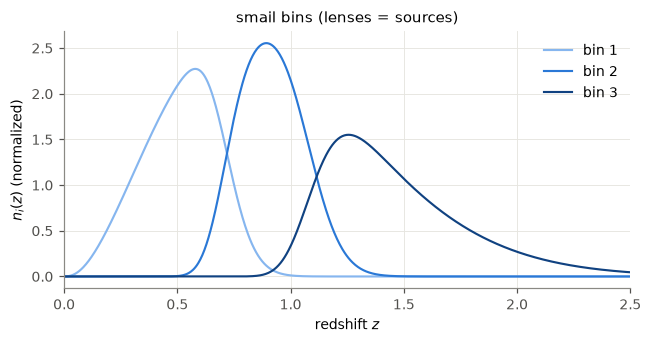

sigma_8 = 0.8241 | CAMB 1.6.6


In [3]:
fig, ax = plt.subplots(figsize=(6, 3.2))
inp = nlv.load_inputs(CFG[NAME])
for i, nz in enumerate(inp['nz_lens']):
    ax.plot(inp['z_nz'], nz, color=nlv.BIN_COLORS[i], label=f'bin {i + 1}')
ax.set_xlim(0, 2.5)
ax.set_xlabel('redshift $z$')
ax.set_ylabel('$n_i(z)$ (normalized)')
ax.set_title(f'{NAME} bins (lenses = sources)', fontsize=10)
ax.legend()
fig.tight_layout()
fig.savefig(FIG / 'nz.png', dpi=140)
plt.show()
print('sigma_8 =', round(float(inp['sigma8']), 4), '| CAMB', inp['camb_version'])

## 2. How large is the beyond-Limber correction?

What is being validated: the difference between cloelib's beyond-Limber and Limber spectra, in units of $\sigma_\ell$ (Smail bins, full model, setup 5, the spectra of each bin with itself), and its $\Delta\chi^2$ for every setup. The codes must agree to a small fraction of this.

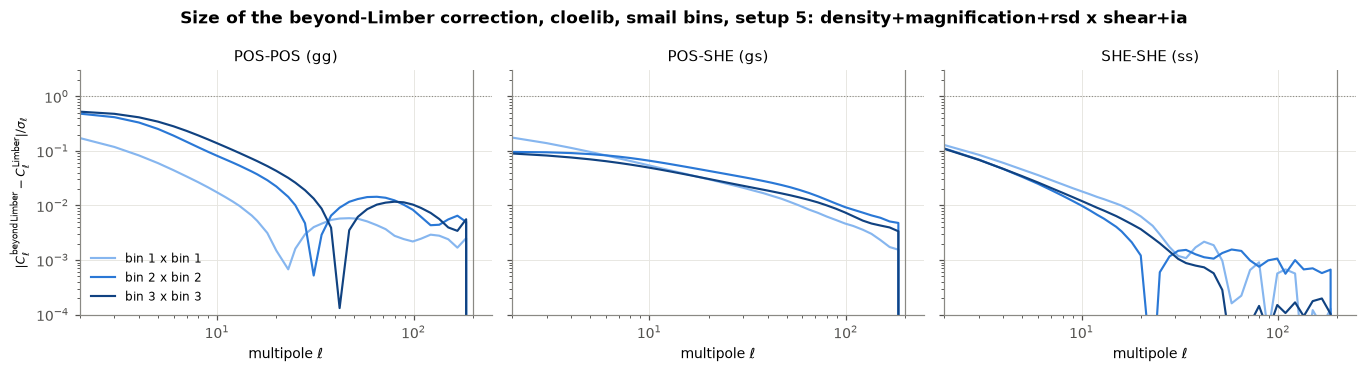

Delta chi^2 of cloelib Limber vs cloelib beyond Limber, 3x2pt, l <= 200
1: density x shear                                  6.10
2: density+magnification x shear                    6.08
3: density+rsd x shear                              5.83
4: density x shear+ia                               9.94
5: density+magnification+rsd x shear+ia             9.75


In [4]:
setup = SETUPS[-1]
res = RES[NAME]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4), sharex=True, sharey=True)
for ax, probe in zip(axes, PROBES):
    nl, lim = res.get(REF, setup, probe, 'nonlimber'), res.get(REF, setup, probe, 'limber')
    d = np.einsum('lii->li', (nl - lim) / res.sigma(setup, probe, 'nonlimber'))
    for i in range(d.shape[1]):
        ax.plot(res.ells, np.abs(d[:, i]), color=nlv.BIN_COLORS[i], label=f'bin {i + 1} x bin {i + 1}')
    ax.axvline(ELL_NL, color=MUTED, lw=0.8)
    ax.axhline(1, color=MUTED, lw=0.7, ls=':')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(1e-4, 3); ax.set_xlim(2, 250)
    ax.set_title(f'{nlv.TITLES[probe]} ({probe})', fontsize=10)
    ax.set_xlabel(r'multipole $\ell$')
axes[0].set_ylabel(r'$|C_\ell^{\rm beyond\,Limber} - C_\ell^{\rm Limber}| / \sigma_\ell$', fontsize=8)
axes[0].legend(fontsize=8)
fig.suptitle(f'Size of the beyond-Limber correction, cloelib, {NAME} bins, setup {short(setup)}', fontsize=11, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG / 'correction_size.png', dpi=140)
plt.show()

print(f'Delta chi^2 of cloelib Limber vs cloelib beyond Limber, 3x2pt, l <= {ELL_NL}')
for s in SETUPS:
    print(f'{short(s):45s} {res.delta_chi2(s, MODE, None, ELL_NL, against=(REF, "limber")):10.2f}')

## 3. Agreement of every code, every setup

The largest $|\Delta C_\ell| / \sigma_\ell$ over all bin pairs and $\ell \leq 200$ (the beyond-Limber range), for each probe; grey cells are spectra the code cannot compute. The colour scale is logarithmic: everything below $0.1\,\sigma$ (lightest blue) is negligible for an analysis.

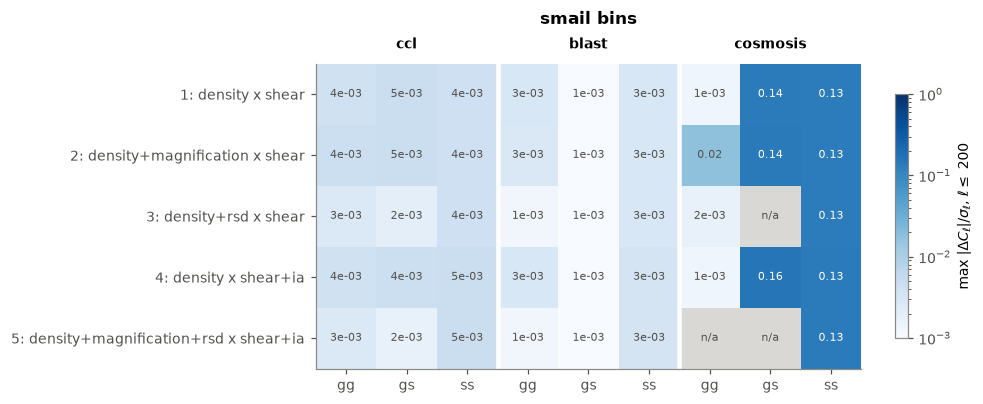

In [5]:
def max_dev(res, code, setup, probe, lo=2, hi=ELL_NL):
    x, ref = res.get(code, setup, probe, MODE), res.get(REF, setup, probe, MODE)
    if x is None:
        return np.nan
    d = (np.abs(x - ref) / res.sigma(setup, probe, MODE))[(res.ells >= lo) & (res.ells <= hi)]
    return np.nanmax(d)


cols = [(c, p) for c in OTHERS for p in PROBES]
fig, ax = plt.subplots(figsize=(8, 3.6))
M = np.array([[max_dev(RES[NAME], c, s, p) for c, p in cols] for s in SETUPS])
ax.set_facecolor('#d9d8d4')
im = ax.imshow(np.ma.masked_invalid(M), cmap='Blues', norm=LogNorm(1e-3, 1), aspect='auto')
for (r, c), v in np.ndenumerate(M):
    ax.text(c, r, 'n/a' if np.isnan(v) else f'{v:.0e}' if v < 0.01 else f'{v:.2f}', ha='center', va='center',
            fontsize=7, color='white' if v > 0.1 else TEXT)
ax.set_xticks(range(len(cols)), [p for _, p in cols])
for k, c in enumerate(OTHERS):
    ax.text(3 * k + 1, -0.75, c, ha='center', fontsize=9, fontweight='bold')
    if k:
        ax.axvline(3 * k - 0.5, color='white', lw=3)
ax.set_yticks(range(len(SETUPS)), [short(s) for s in SETUPS])
ax.set_title(f'{NAME} bins', fontsize=11, fontweight='bold', pad=26)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label=r'max $|\Delta C_\ell| / \sigma_\ell$, $\ell \leq$' + f' {ELL_NL}')
fig.savefig(FIG / 'max_deviation.png', dpi=140, bbox_inches='tight')
plt.show()

The same comparison for the whole 3x2pt data vector: $\Delta\chi^2$ of each code against cloelib. For reference, the last column is the $\Delta\chi^2$ of the beyond-Limber correction itself (section 2).

In [6]:
for name in [NAME]:
    res = RES[name]
    print(f'\n{name} bins: Delta chi^2 against cloelib (3x2pt, Knox with noise)')
    print(f'{"setup":45s} ' + ' '.join(f'{c + " l<=" + str(L):>15s}' for c in OTHERS for L in (ELL_NL, ELL_MAX))
          + f' {"correction l<=" + str(ELL_NL):>17s}')
    for s in SETUPS:
        row = [res.delta_chi2(s, MODE, c, L) for c in OTHERS for L in (ELL_NL, ELL_MAX)]
        corr = res.delta_chi2(s, MODE, None, ELL_NL, against=(REF, 'limber'))
        print(f'{short(s):45s} ' + ' '.join(f'{"n/a" if v != v else f"{v:.3g}":>15s}' for v in row) + f' {corr:17.3g}')


smail bins: Delta chi^2 against cloelib (3x2pt, Knox with noise)
setup                                              ccl l<=200     ccl l<=1000    blast l<=200   blast l<=1000 cosmosis l<=200 cosmosis l<=1000 correction l<=200
1: density x shear                                    0.00198         0.00252         0.00174          0.0118            4.29            4.29               6.1
2: density+magnification x shear                      0.00196          0.0025         0.00174          0.0118            4.22            4.22              6.08
3: density+rsd x shear                                0.00097          0.0251         0.00165          0.0298             n/a             n/a              5.83


4: density x shear+ia                                 0.00191         0.00244         0.00181          0.0127            9.48            9.48              9.94
5: density+magnification+rsd x shear+ia              0.000985          0.0259         0.00172          0.0315             n/a             n/a              9.75


## 4. The full model, multipole by multipole

Setup 5 (every term): at each $\ell$, the largest $|\Delta C_\ell| / \sigma_\ell$ over the bin pairs of each probe. CosmoSIS cannot compute galaxy RSD x shear nor RSD x magnification, so it is missing from POS-POS and POS-SHE here. The solid line is cloelib's switch to Limber, the dotted one Blast's.

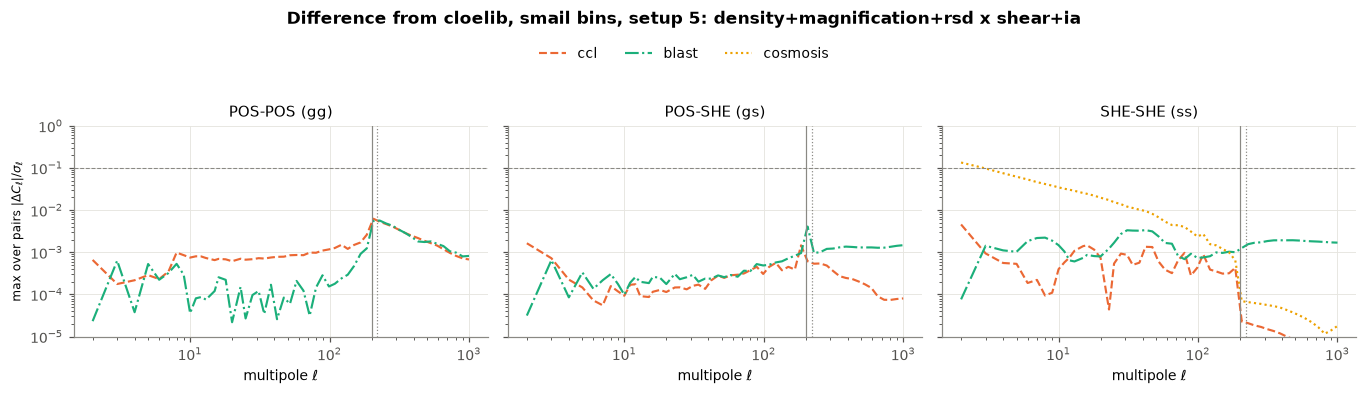

In [7]:
setup = SETUPS[-1]
res = RES[NAME]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharex=True, sharey=True)
for ax, probe in zip(axes, PROBES):
    ref, sig = res.get(REF, setup, probe, MODE), res.sigma(setup, probe, MODE)
    for c in OTHERS:
        x = res.get(c, setup, probe, MODE)
        if x is None:
            continue
        d = np.abs(x - ref) / sig
        env = np.array([np.nanmax([d[l, i, j] for i, j in res.pairs(probe)]) for l in range(len(res.ells))])
        ax.plot(res.ells, env, label=c, **nlv.STYLE[c])
    ax.axvline(ELL_NL, color=MUTED, lw=0.8)
    ax.axvline(220, color=MUTED, lw=0.8, ls=':')
    ax.axhline(0.1, color=MUTED, lw=0.7, ls='--')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(1e-5, 1)
    ax.set_title(f'{nlv.TITLES[probe]} ({probe})', fontsize=10)
    ax.set_xlabel(r'multipole $\ell$')
axes[0].set_ylabel(r'max over pairs $|\Delta C_\ell| / \sigma_\ell$', fontsize=8)
handles = {h.get_label(): h for ax in axes for h in ax.get_legend_handles_labels()[0]}
fig.legend(handles.values(), handles.keys(), loc='upper center', ncol=len(handles), bbox_to_anchor=(0.5, 0.92))
fig.suptitle(f'Difference from cloelib, {NAME} bins, setup {short(setup)}', fontsize=11, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.86))
fig.savefig(FIG / 'full_model_residuals.png', dpi=140)
plt.show()

## 5. The spectra and the MAER, setup by setup

For each setup, two figures (the same as `results/smail/<setup>/cl__nonlimber.png` and `maer__nonlimber.png`, drawn by the same code, `nlv.plotters`):
- **Spectra**: $\ell(\ell+1)C_\ell/2\pi$ of every pair of bins, all codes on top of each other, with cloelib's Limber-only curve (dashed grey) to show where the beyond-Limber correction matters.
- **MAER**: the absolute difference of each code (one row each) from cloelib, in percent of the cosmic-variance error (no noise), $100\,|\Delta C_\ell| / \sigma^{\rm CV}_\ell$, for the spectra of each bin with itself.

`SHOW` picks the setups (all by default).

In [8]:
PLOT = nlv.plotters(CFG[NAME], RES[NAME])
SHOW = SETUPS   # e.g. SETUPS[-1:] for the full model only

### Setup 1: density x shear

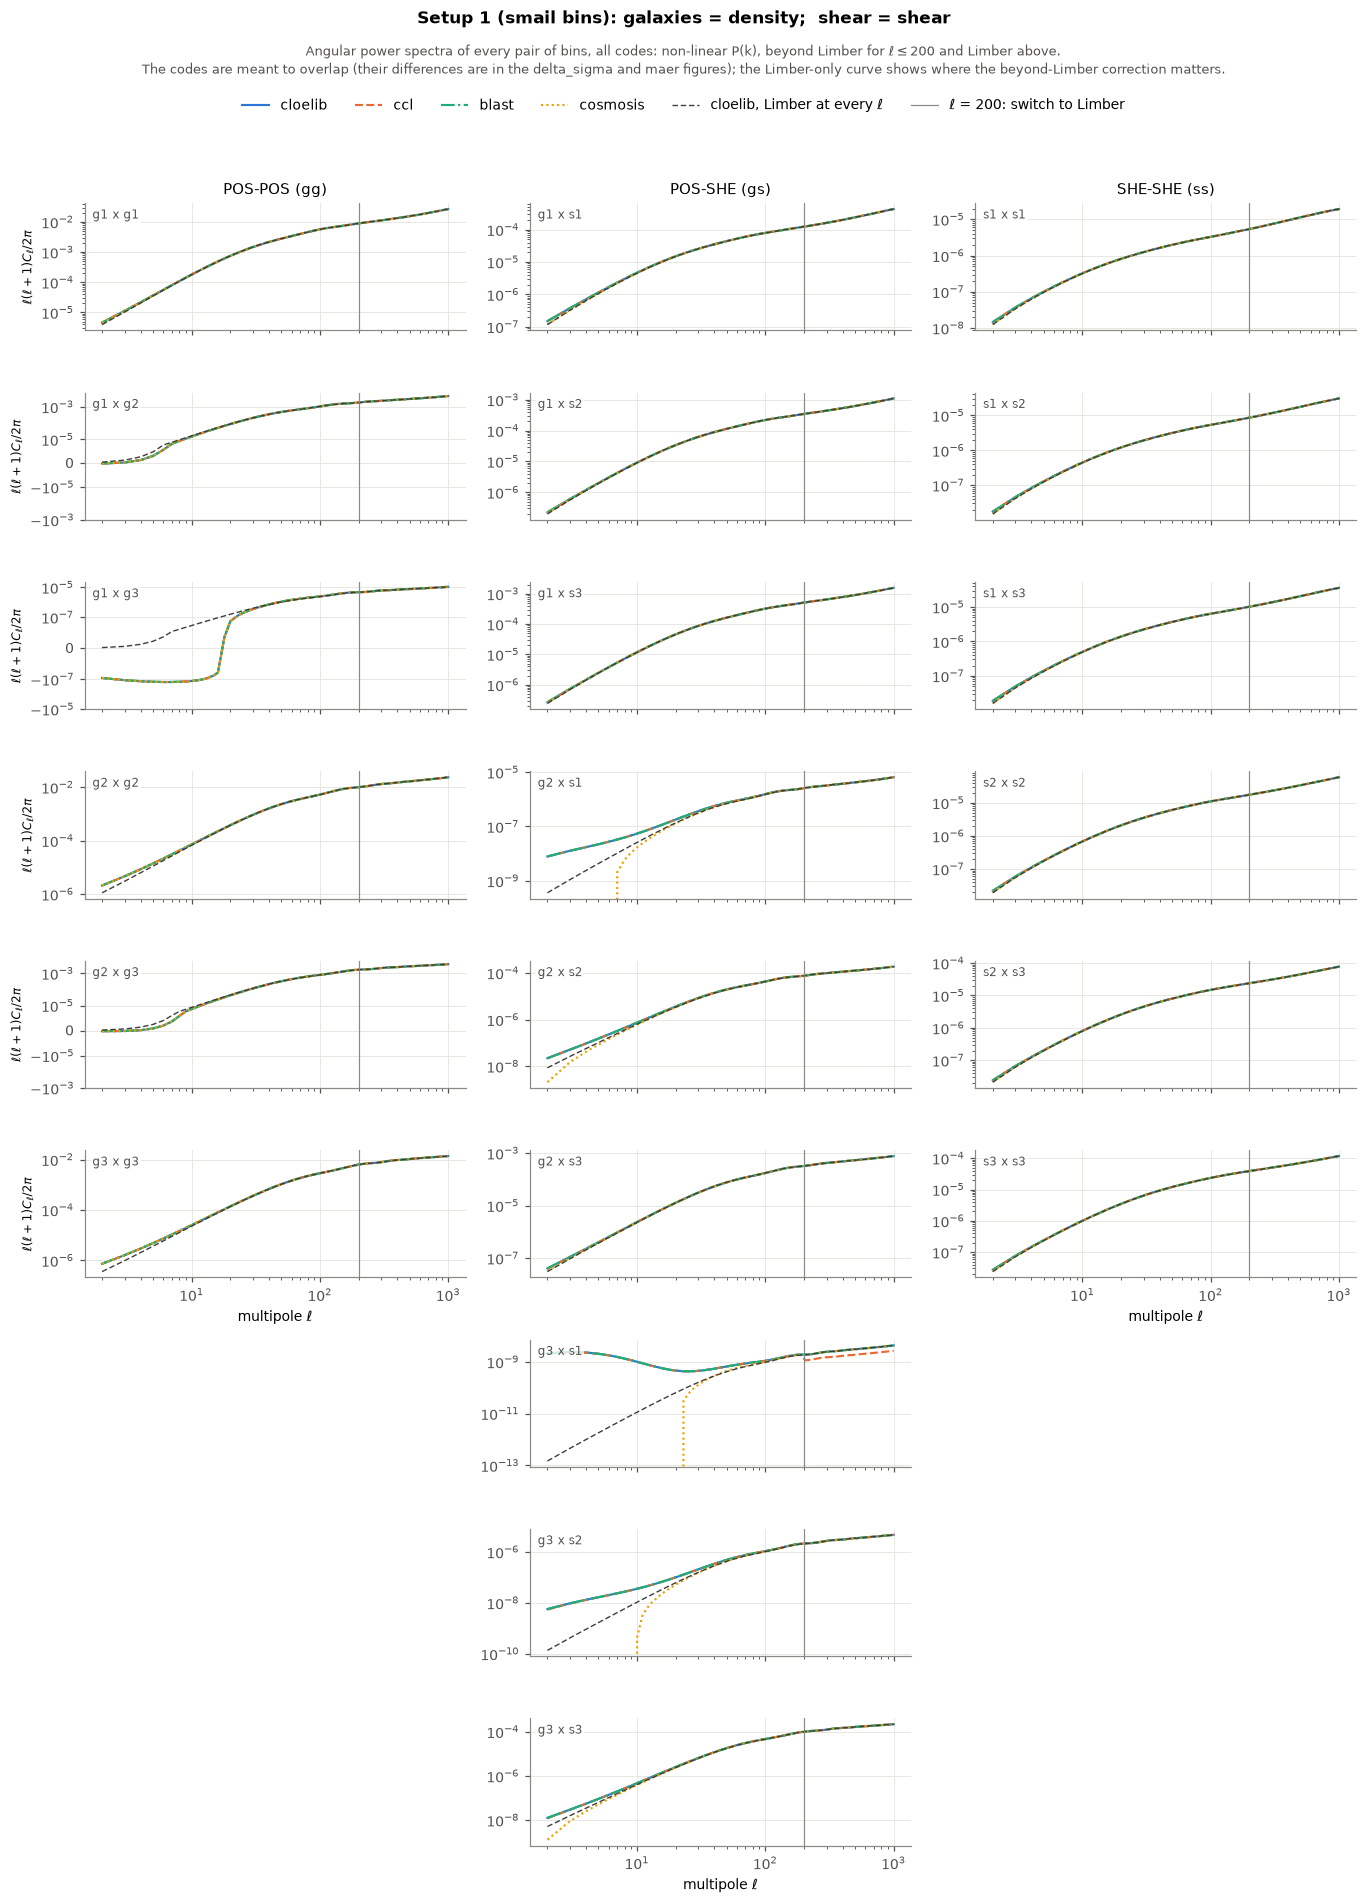

In [9]:
setup = SETUPS[0]
if setup in SHOW:
    PLOT.plot_cl(setup, MODE, None)
    plt.show()

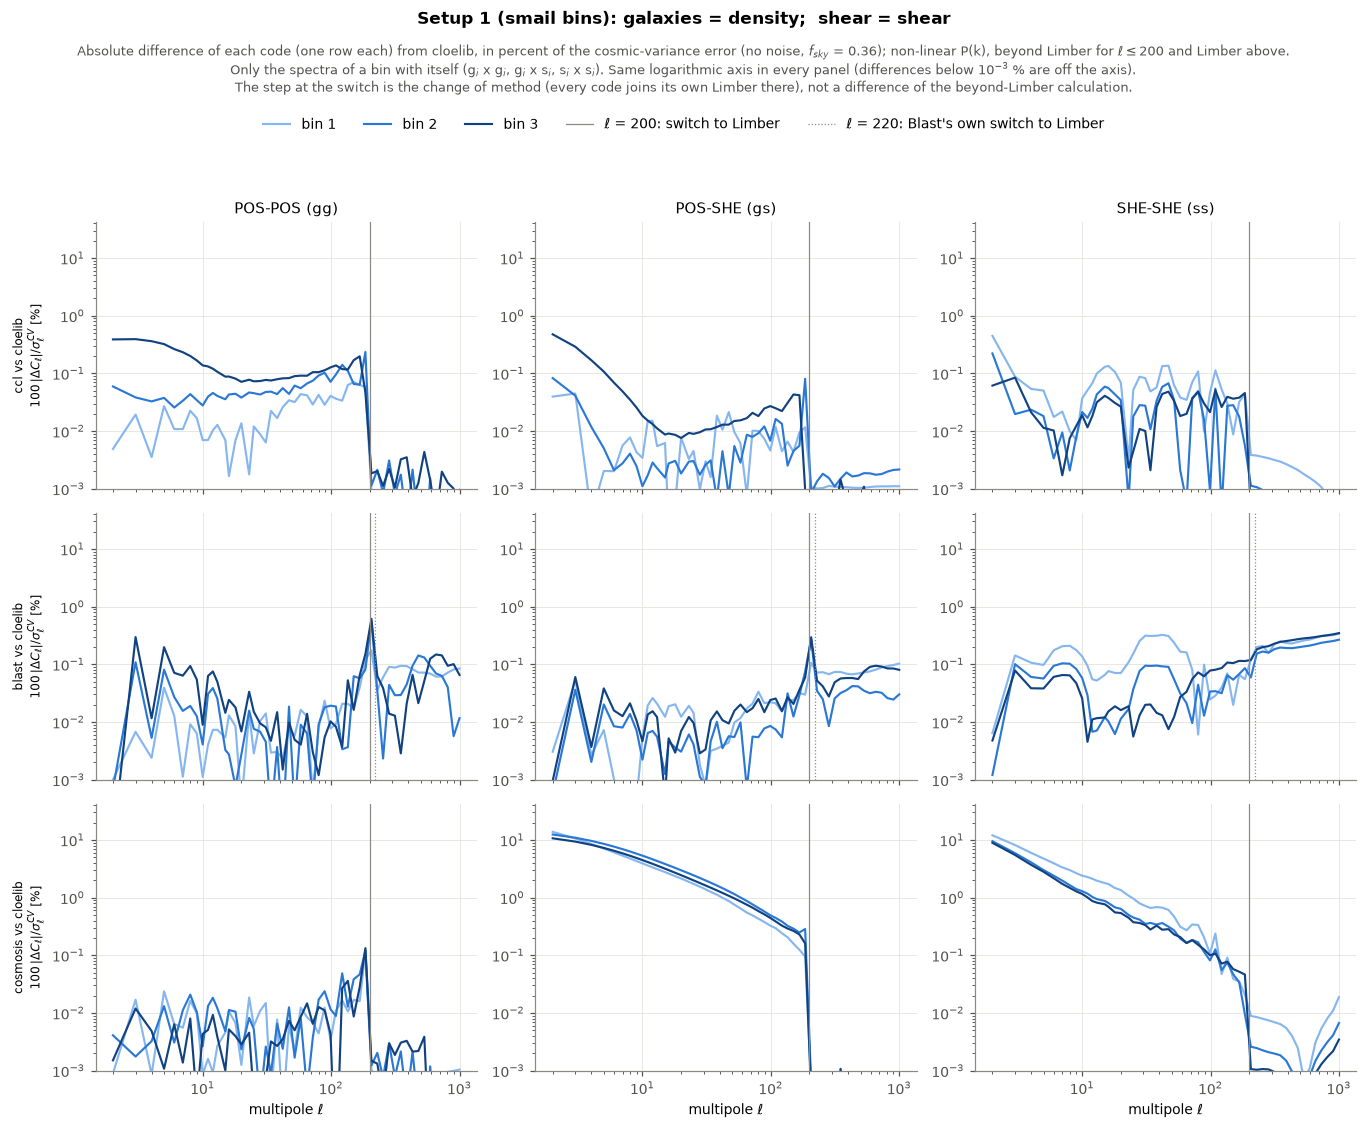

In [10]:
if setup in SHOW:
    PLOT.plot_maer(setup, MODE, None)
    plt.show()

### Setup 2: density + magnification x shear

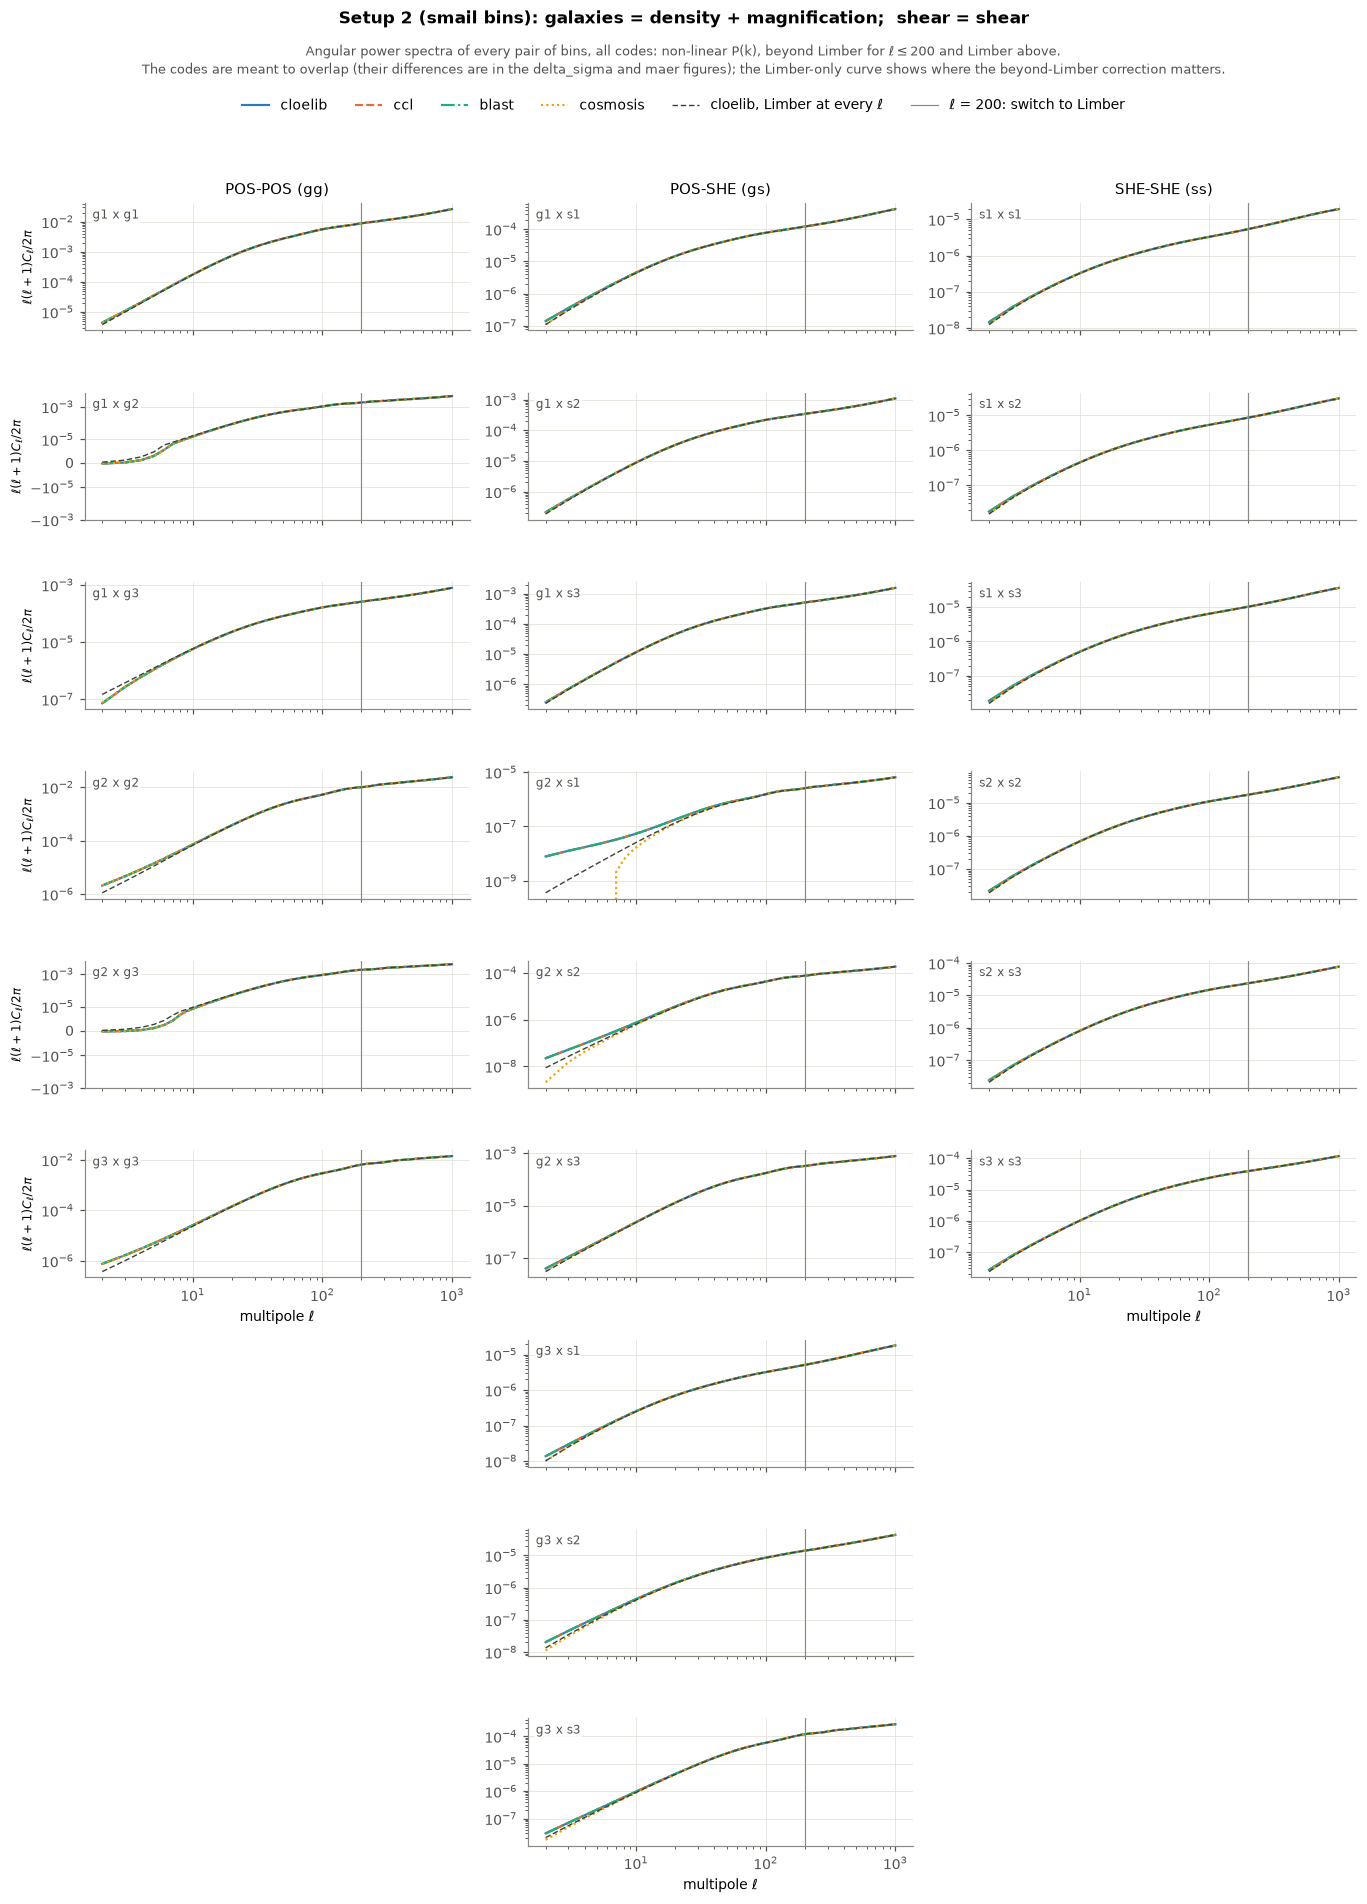

In [11]:
setup = SETUPS[1]
if setup in SHOW:
    PLOT.plot_cl(setup, MODE, None)
    plt.show()

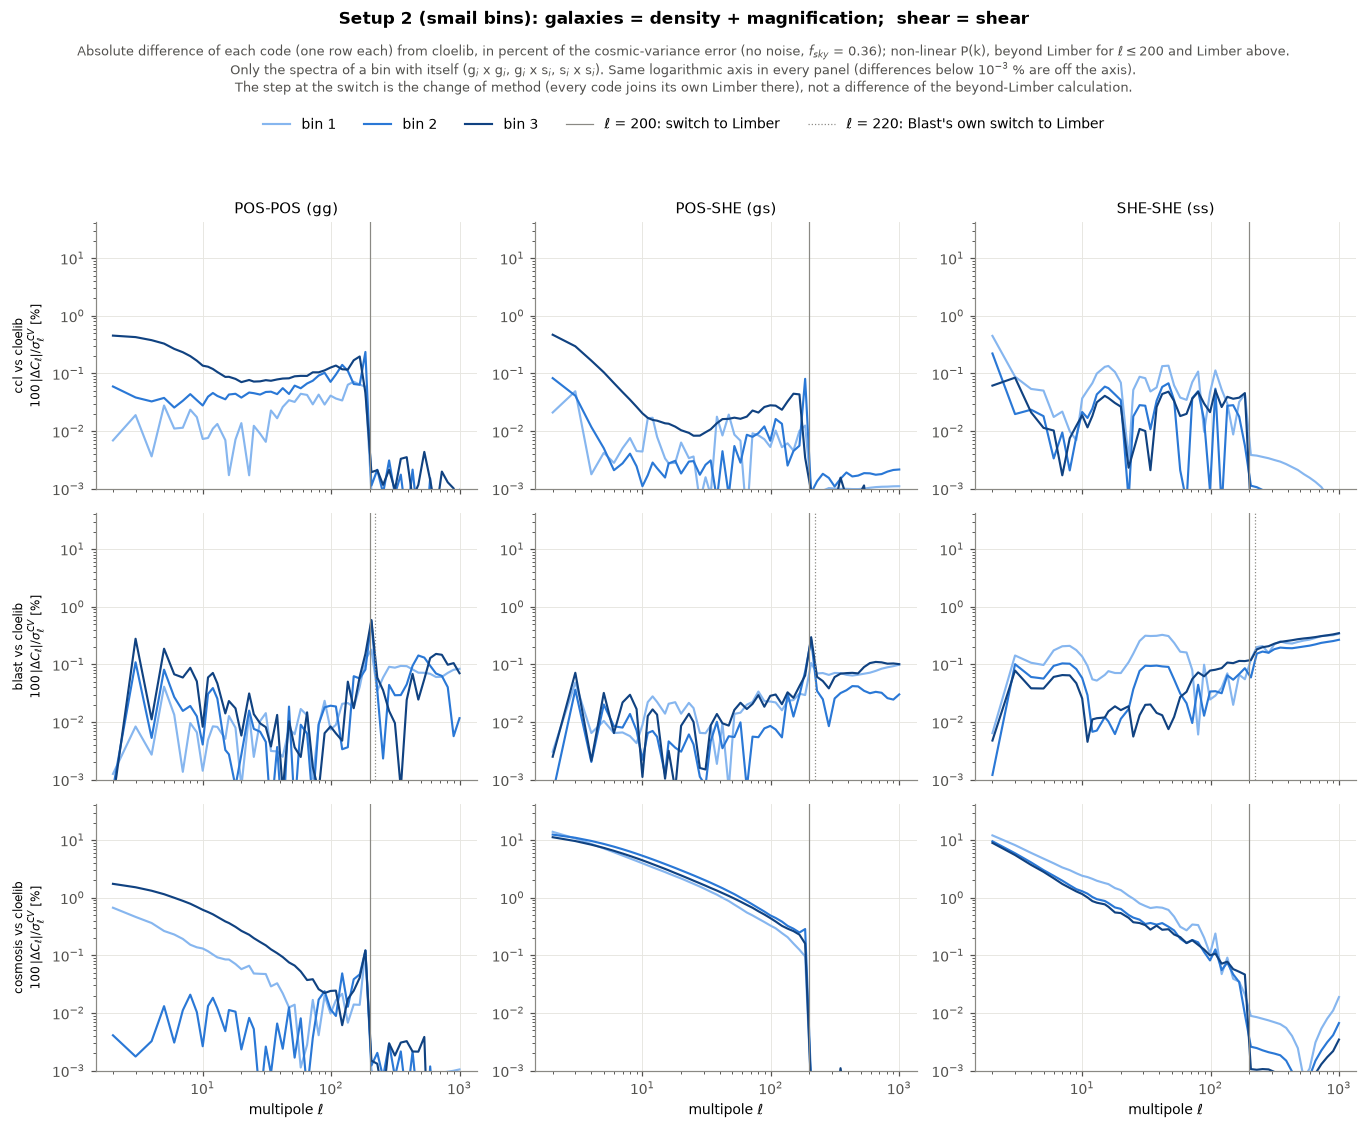

In [12]:
if setup in SHOW:
    PLOT.plot_maer(setup, MODE, None)
    plt.show()

### Setup 3: density + rsd x shear

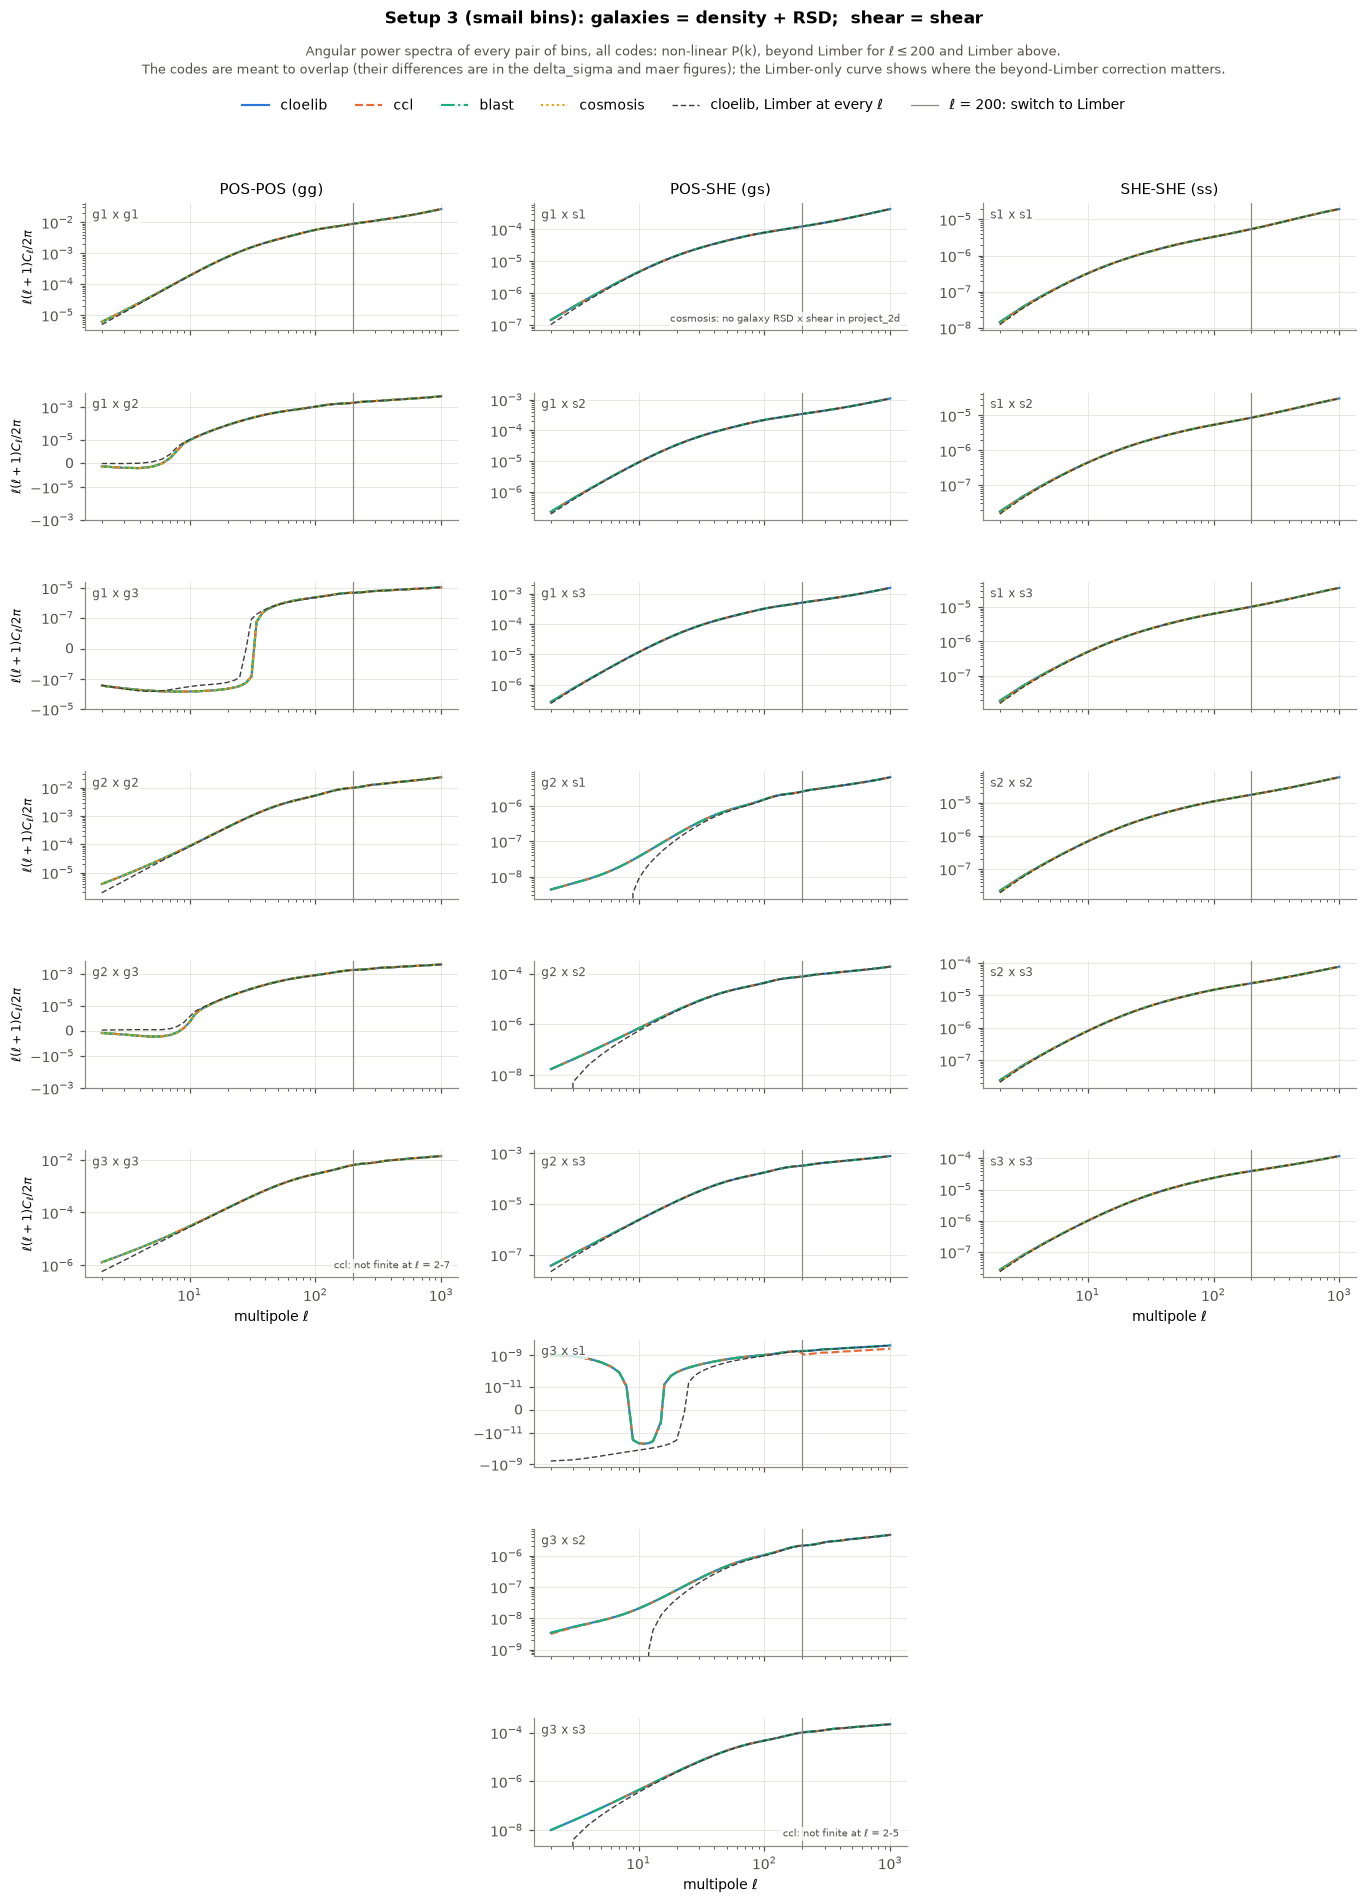

In [13]:
setup = SETUPS[2]
if setup in SHOW:
    PLOT.plot_cl(setup, MODE, None)
    plt.show()

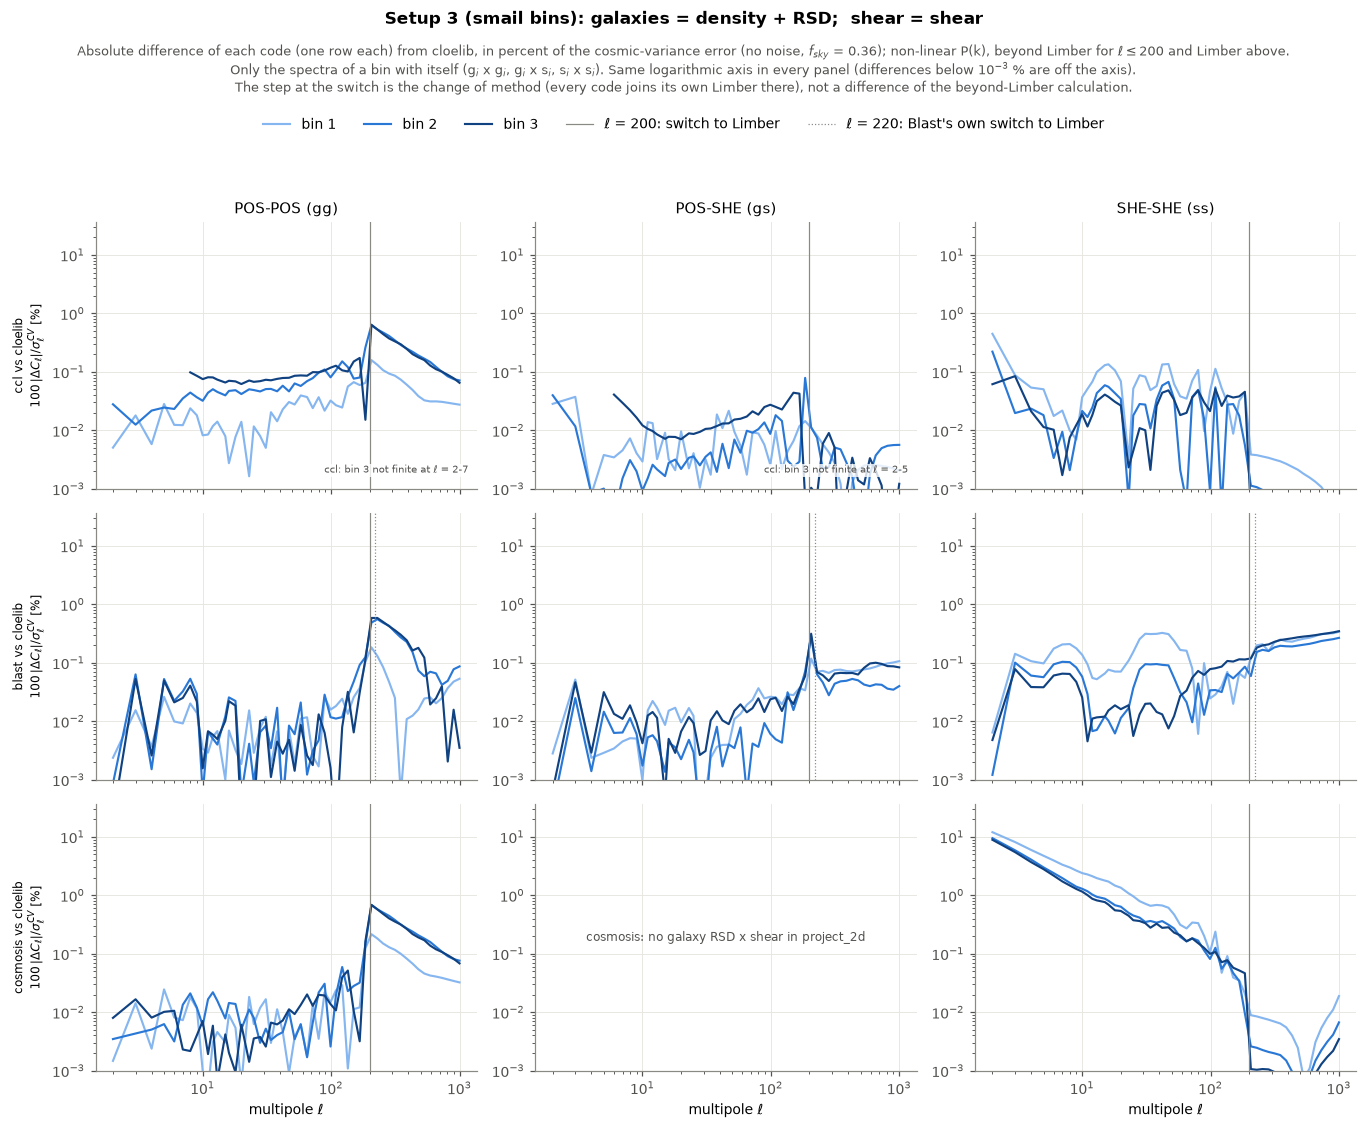

In [14]:
if setup in SHOW:
    PLOT.plot_maer(setup, MODE, None)
    plt.show()

### Setup 4: density x shear + ia

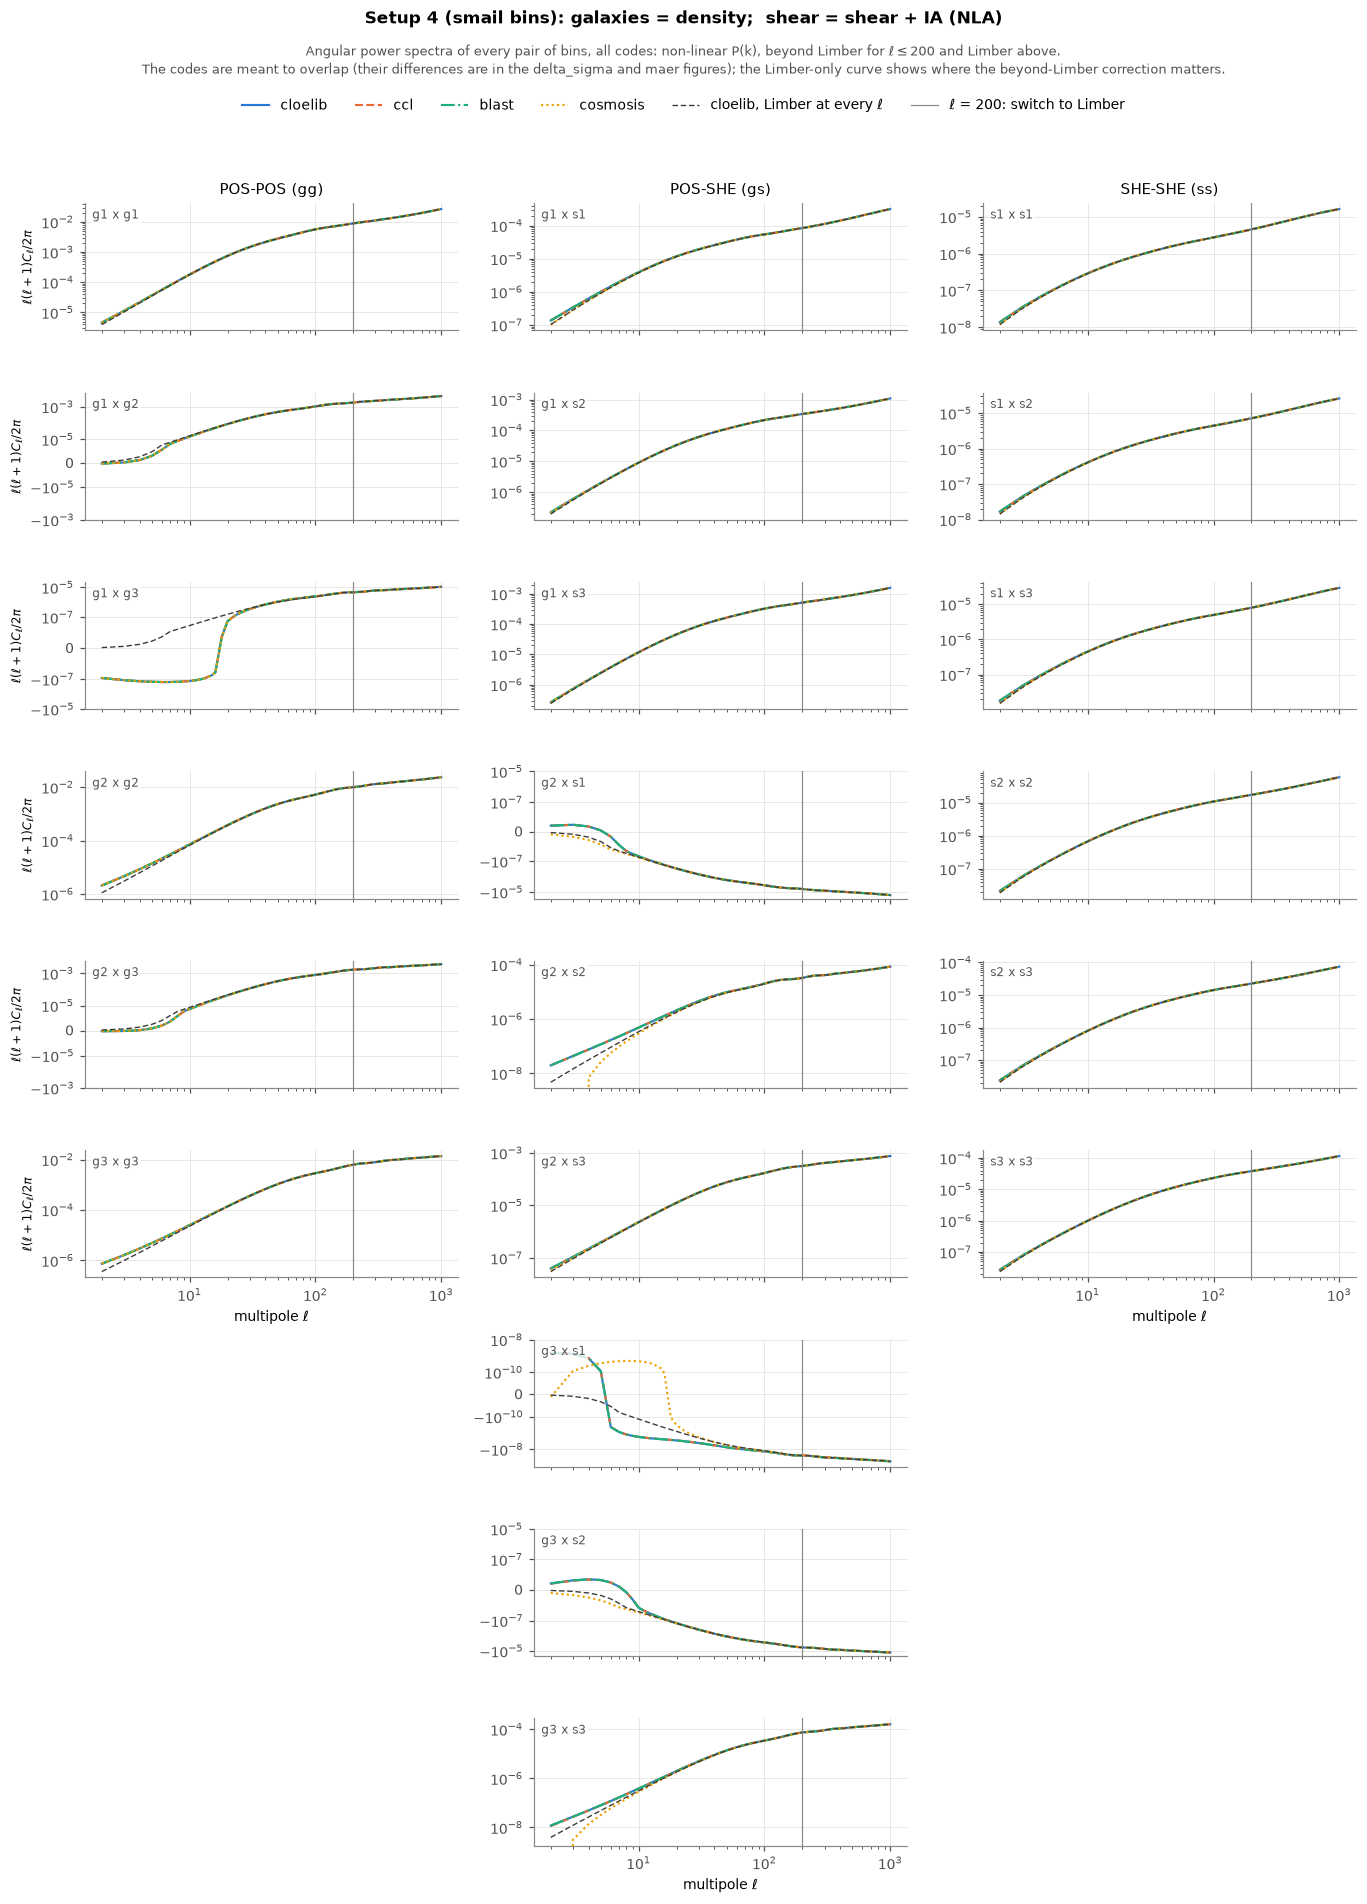

In [15]:
setup = SETUPS[3]
if setup in SHOW:
    PLOT.plot_cl(setup, MODE, None)
    plt.show()

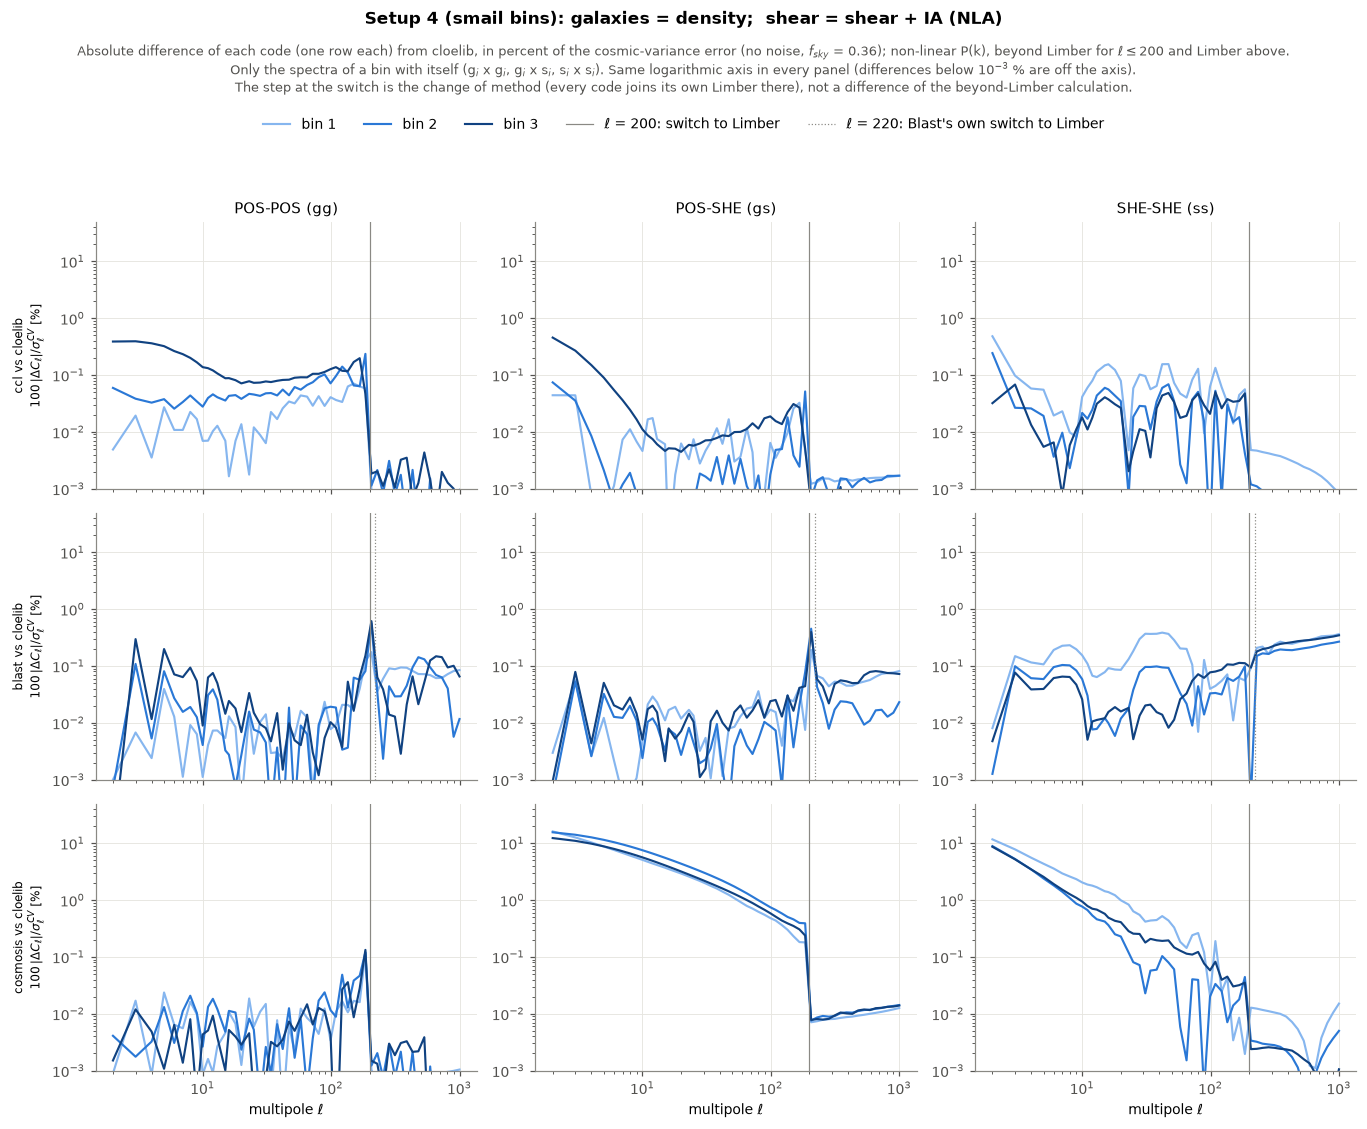

In [16]:
if setup in SHOW:
    PLOT.plot_maer(setup, MODE, None)
    plt.show()

### Setup 5: density + magnification + rsd x shear + ia

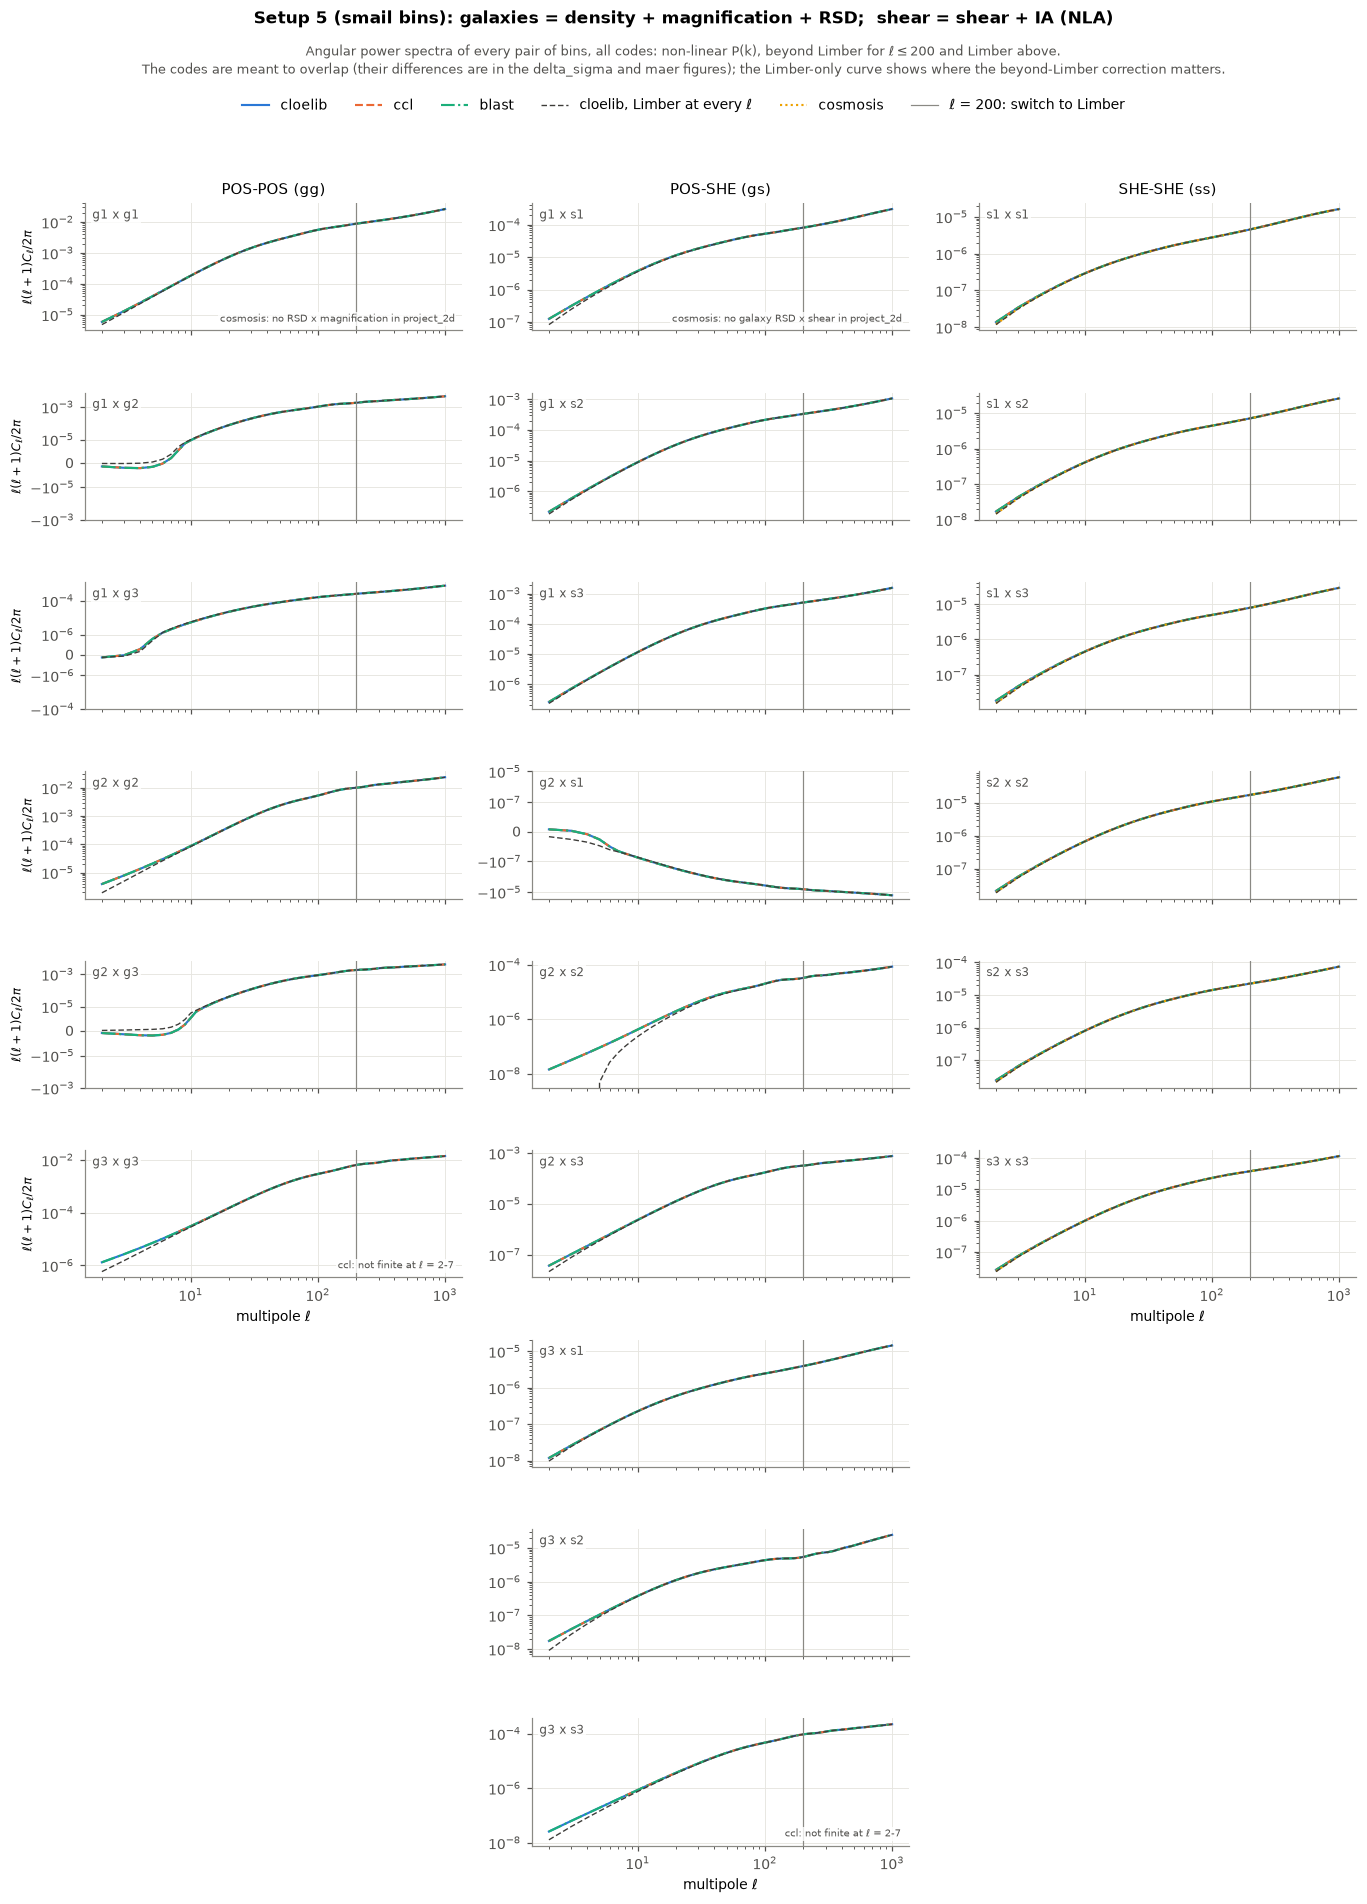

In [17]:
setup = SETUPS[4]
if setup in SHOW:
    PLOT.plot_cl(setup, MODE, None)
    plt.show()

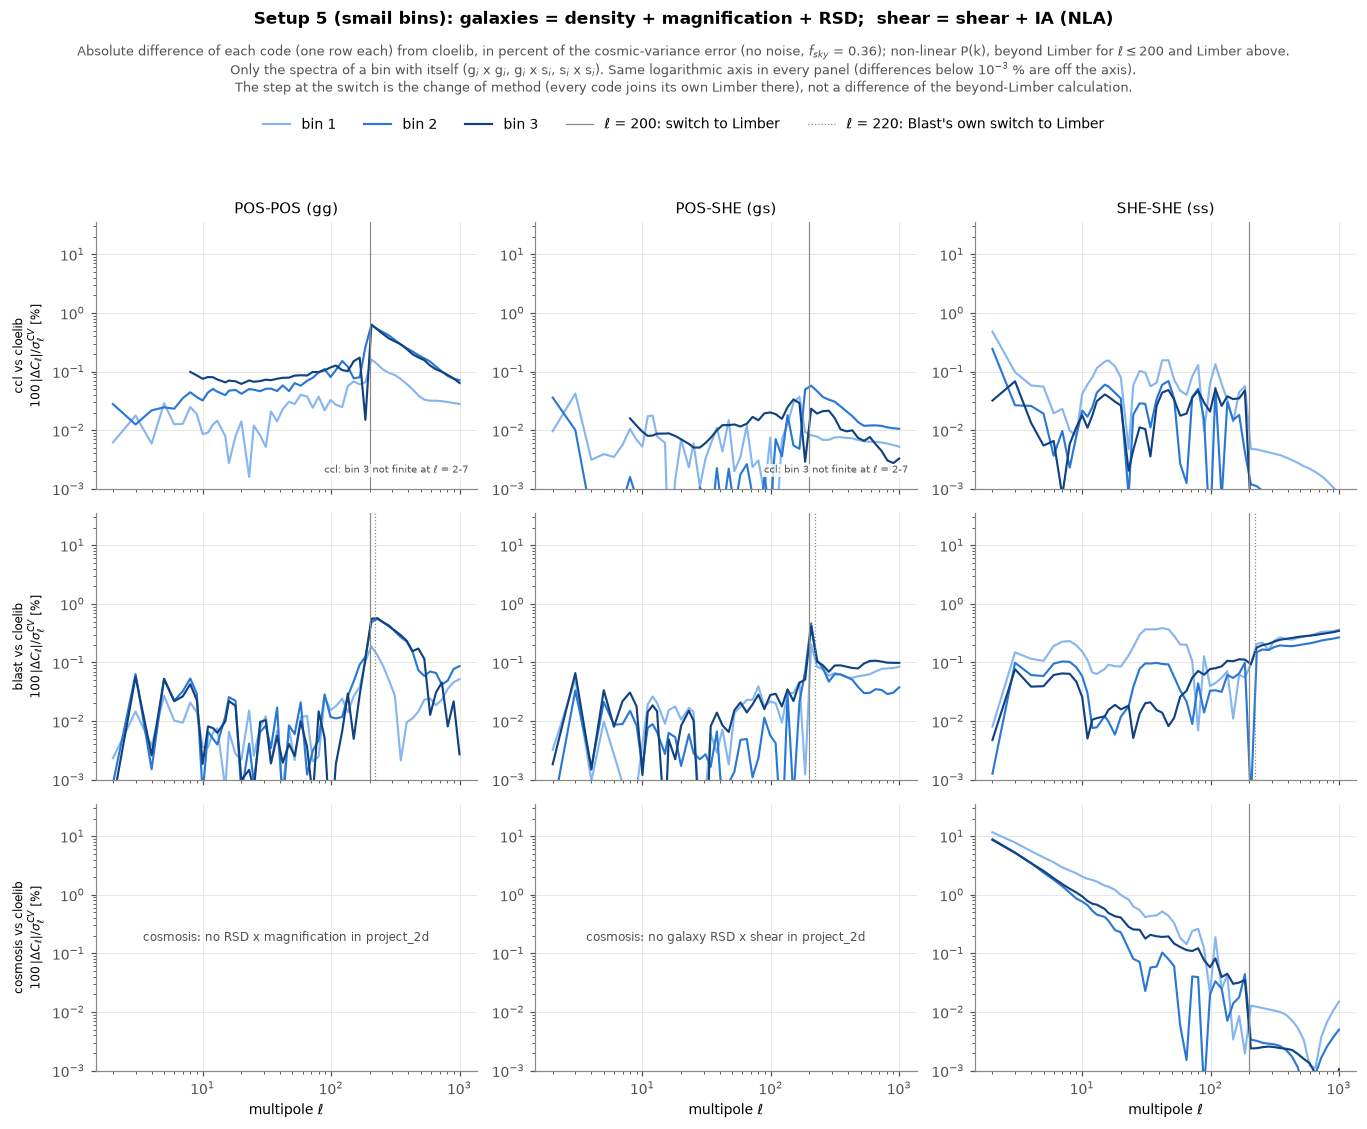

In [18]:
if setup in SHOW:
    PLOT.plot_maer(setup, MODE, None)
    plt.show()

## 6. Where the references are not references

Known limitations of the other codes, which explain the largest numbers above (they are not errors of cloelib):
- **CosmoSIS** puts the *Limber* lensing kernels inside its exact Bessel integral, so its shear, magnification and IA spectra are low at $\ell \lesssim 20$: it is not a beyond-Limber reference for those terms. It cannot compute RSD x magnification, galaxy RSD x shear and magnification x IA.
- **pyccl**: its Limber with RSD returns NaN at the lowest $\ell$ for the highest-$z$ bin (those multipoles are left out of its residuals).
- **Blast.jl** switches to Limber at its own fixed $\ell = 220$, without RSD in its Limber part, so above $\ell = 200$ it is compared with cloelib's Limber and its non-linear shear departs from the others.

The cell lists the multipoles where a code returned no finite value.

In [19]:
for name in [NAME]:
    res = RES[name]
    for c in OTHERS:
        for s in SETUPS:
            for p in PROBES:
                x = res.get(c, s, p, MODE)
                if x is not None and not np.all(np.isfinite(x)):
                    bad = res.ells[~np.all(np.isfinite(x), axis=(1, 2))]
                    print(f'{name:8s} {c:8s} {short(s):45s} {p}: not finite at ell = {bad.astype(int).tolist()}')

smail    ccl      3: density+rsd x shear                        gg: not finite at ell = [2, 3, 4, 5, 6, 7]
smail    ccl      3: density+rsd x shear                        gs: not finite at ell = [2, 3, 4, 5]
smail    ccl      5: density+magnification+rsd x shear+ia       gg: not finite at ell = [2, 3, 4, 5, 6, 7]
smail    ccl      5: density+magnification+rsd x shear+ia       gs: not finite at ell = [2, 3, 4, 5, 6, 7]


## 7. Findings

Spectra of cloelib `f7bfbdc` (`feature/no-limber`), `nonlimber` mode (non-linear $P(k)$, beyond Limber for $\ell \leq 200$), Smail bins.

| # | finding | numbers | where |
|---|---|---|---|
| 1 | **The beyond-Limber correction matters**: replacing cloelib's beyond-Limber spectra with Limber ones changes the 3x2pt $\chi^2$ by 6–10, up to half a $\sigma$ per multipole in POS-POS at $\ell < 10$ | $\Delta\chi^2_{\ell \leq 200}$ = 5.8–9.9 | §2, §5 |
| 2 | **cloelib agrees with Blast.jl and pyccl for every term** (density, magnification, RSD, shear, NLA), to about a thousandth of that correction | max $\lvert\Delta C_\ell\rvert/\sigma_\ell \leq 5 \times 10^{-3}$ for $\ell \leq 200$; $\Delta\chi^2_{\ell \leq 200} \leq 0.002$ in every setup | §3, §4, §5 |
| 3 | **Above the switch, cloelib keeps RSD in its Limber spectra**; the references do not (CosmoSIS) or almost not (pyccl). This, not the beyond-Limber part, is pyccl's larger $\Delta\chi^2$ up to $\ell = 1000$ in setups 3 and 5. At $\ell = 206$, where Blast is still beyond Limber, the RSD effect of Blast and cloelib agree (bin 3: 0.08% of $C_\ell$ for both) | pyccl $\Delta\chi^2_{\ell \leq 1000}$ = 0.025–0.026; gg $\ell > 200$: $6 \times 10^{-3}\,\sigma$ | §3, §4, §5 |
| 4 | **Blast.jl above $\ell = 220$** is in its own Limber (no RSD, non-linear shear slightly different): its $\Delta\chi^2$ up to $\ell = 1000$ is 0.01–0.03, all from there | $\Delta\chi^2_{\ell \leq 200} \leq 0.002$ | §3, §4, §5 |
| 5 | **CosmoSIS is a reference only for galaxy density and RSD**: POS-POS agrees ($\leq 1.7 \times 10^{-2}\,\sigma$), while its Limber lensing kernels inside the exact integral make shear, magnification and IA low at $\ell \lesssim 20$ | POS-SHE up to $0.16\,\sigma$, SHE-SHE up to $0.14\,\sigma$; $\Delta\chi^2$ = 4.2–9.5 | §3, §4, §5, §6 |
| 6 | **pyccl's Limber with RSD returns NaN** at the lowest $\ell$ for the highest-$z$ bin; those multipoles are left out of its residuals | $\ell \leq 7$ | §6 |

**Conclusion.** Within the precision of the two independent references that compute every term beyond Limber (Blast.jl with the same T-tildes, pyccl with FKEM), cloelib's beyond-Limber 3x2pt is validated for density, magnification, RSD, shear and NLA for broad Euclid-like Smail bins: the differences are below $0.005\,\sigma$ per spectrum and $\Delta\chi^2 \leq 0.002$, against a correction of $\Delta\chi^2$ = 6–10.